# Week 4: Tracking People

I use YOLO11n to detect people and ByteTrack to give them IDs across video frames. Then I compare the number of tracker IDs with a separate visual count and inspect one ID change.

The sample has 795 frames at 10 FPS. The source video, visual person ledger and review notes are in `data/`.

Install `requirements.txt`, open this notebook from the project folder, and run all cells from the top. This notebook performs fresh inference; it does not read a cached tracking run.

## 1. Import the libraries

In [1]:
from pathlib import Path
import argparse
import hashlib
import importlib.metadata
import json
import subprocess

import cv2
import imageio_ffmpeg
import pandas as pd
from ultralytics import YOLO

## 2. Set the paths

In [2]:
baseDir = Path.cwd()
inputPath = baseDir / "data" / "vtest.avi"
outputDir = baseDir / "outputs"
resultDir = baseDir / "results"
modelDir = baseDir / "models"
for folder in [outputDir, resultDir, modelDir]:
    folder.mkdir(exist_ok=True)

rawPath = outputDir / "people_tracked_raw.mp4"
outputPath = outputDir / "people_tracked.mp4"
trackerPath = baseDir / "bytetrack.yaml"
confidenceThreshold = 0.1
if not inputPath.is_file():
    raise FileNotFoundError(f"Video not found: {inputPath}")
if inputPath in [rawPath.resolve(), outputPath.resolve()]:
    raise ValueError("Choose an input outside the output video paths.")

## 3. Load the model and read the video

In [3]:
modelPath = modelDir / "yolo11n.pt"
model = YOLO(str(modelPath))
cap = cv2.VideoCapture(str(inputPath))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
totalFrames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
if not cap.isOpened() or width <= 0 or height <= 0 or not 0 < fps < 1000:
    cap.release()
    raise ValueError("Could not read valid video details.")

writer = cv2.VideoWriter(str(rawPath), cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))
if not writer.isOpened():
    cap.release()
    writer.release()
    raise RuntimeError("Could not create the output video.")
print("Input:", width, "x", height, "| FPS:", fps, "| Frames:", totalFrames)

Input: 768 x 576 | FPS: 10.0 | Frames: 795


## 4. Track people and store each ID once

In [4]:
seenIds = set()
trackRows = []
frameRows = []
frameNumber = 0
try:
    while True:
        success, frame = cap.read()
        if not success:
            break
        result = model.track(frame, persist=True, classes=[0], conf=confidenceThreshold,
                             tracker=str(trackerPath), imgsz=640, iou=0.7,
                             device="cpu", verbose=False)[0]
        peopleInFrame = 0
        if result.boxes.is_track:
            for box in result.boxes:
                trackId = int(box.id.item())
                score = float(box.conf.item())
                x1, y1, x2, y2 = [float(value) for value in box.xyxy[0].tolist()]
                seenIds.add(trackId)
                peopleInFrame += 1
                trackRows.append({"frameNumber": frameNumber, "timeSeconds": frameNumber / fps,
                                  "trackId": trackId, "confidence": score,
                                  "x1": x1, "y1": y1, "x2": x2, "y2": y2})
                color = (40 + trackId * 43 % 190, 70 + trackId * 61 % 170, 50 + trackId * 89 % 190)
                cv2.rectangle(frame, (int(x1), int(y1)), (int(x2), int(y2)), color, 2)
                label = f"ID {trackId}"
                labelX = max(0, min(int(x1), width - 75))
                labelY = min(height - 8, max(58, int(y1) - 8))
                cv2.putText(frame, label, (labelX, labelY), cv2.FONT_HERSHEY_SIMPLEX, 0.48, (0, 0, 0), 3)
                cv2.putText(frame, label, (labelX, labelY), cv2.FONT_HERSHEY_SIMPLEX, 0.48, color, 1)
        frameRows.append({"frameNumber": frameNumber, "timeSeconds": frameNumber / fps,
                          "peopleInFrame": peopleInFrame, "uniqueTrackIds": len(seenIds)})
        cv2.rectangle(frame, (0, 0), (width, 44), (25, 25, 25), -1)
        cv2.putText(frame, f"Frame {frameNumber} | Visible tracks: {peopleInFrame} | Unique IDs: {len(seenIds)}",
                    (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.56, (255, 255, 255), 1)
        writer.write(frame)
        if frameNumber in [0, totalFrames // 3, totalFrames - 1]:
            if not cv2.imwrite(str(outputDir / f"tracked_frame_{frameNumber:04d}.jpg"), frame):
                raise RuntimeError("Could not save a preview.")
        frameNumber += 1
        if frameNumber % 100 == 0:
            print("Processed frames:", frameNumber)
finally:
    cap.release()
    writer.release()
if frameNumber != totalFrames or frameNumber == 0:
    raise ValueError("The decoded frame count does not match the input.")

Processed frames: 100


Processed frames: 200


Processed frames: 300


Processed frames: 400


Processed frames: 500


Processed frames: 600


Processed frames: 700


## 5. Save the tracking tables

In [5]:
trackDf = pd.DataFrame(trackRows, columns=["frameNumber", "timeSeconds", "trackId", "confidence", "x1", "y1", "x2", "y2"])
frameDf = pd.DataFrame(frameRows)
trackDf.to_csv(resultDir / "tracks.csv", index=False)
frameDf.to_csv(resultDir / "frame_counts.csv", index=False)
trackSummary = trackDf.groupby("trackId").agg(firstFrame=("frameNumber", "min"),
                                            lastFrame=("frameNumber", "max"),
                                            observedFrames=("frameNumber", "size"))
trackSummary.to_csv(resultDir / "track_summary.csv")
runInfo = {"model": "yolo11n.pt", "tracker": "ByteTrack", "confidence": confidenceThreshold,
           "imageSize": 640, "nmsIou": 0.7, "classes": [0], "device": "cpu",
           "width": width, "height": height, "fps": fps, "frames": frameNumber,
           "uniqueTrackIds": len(seenIds), "trackIds": sorted(seenIds), "frameIndexing": "zero-based",
           "inputSha256": hashlib.sha256(inputPath.read_bytes()).hexdigest(),
           "modelSha256": hashlib.sha256(modelPath.read_bytes()).hexdigest(),
           "trackerSha256": hashlib.sha256(trackerPath.read_bytes()).hexdigest(),
           "packages": {name: importlib.metadata.version(name) for name in
                        ["ultralytics", "torch", "torchvision", "opencv-python", "numpy", "lap"]}}
(resultDir / "run_info.json").write_text(json.dumps(runInfo, indent=2) + "\n", encoding="utf-8")

1053

## 6. Save a browser-compatible output video

In [6]:
subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), "-hide_banner", "-loglevel", "error", "-y",
                "-i", str(rawPath), "-an", "-c:v", "libx264", "-crf", "20", "-pix_fmt", "yuv420p",
                "-movflags", "+faststart", str(outputPath)], check=True)
print("Unique tracker IDs:", len(seenIds))
print("These are track IDs, not guaranteed unique real people.")
print("Saved:", outputPath)

Unique tracker IDs: 38
These are track IDs, not guaranteed unique real people.
Saved: C:\Users\LENOVO\AppData\Local\Temp\codex-week4-validation\clean-project\outputs\people_tracked.mp4


## 7. Read the tracking results and visual review

In [7]:
from pathlib import Path
import json

import cv2
import matplotlib.pyplot as plt
import pandas as pd

baseDir = Path.cwd()
resultDir = baseDir / "results"
outputDir = baseDir / "outputs"
runInfo = json.loads((resultDir / "run_info.json").read_text(encoding="utf-8"))
review = json.loads((baseDir / "data" / "manual_review.json").read_text(encoding="utf-8"))
manualDf = pd.read_csv(baseDir / "data" / "manual_people.csv")
trackDf = pd.read_csv(resultDir / "tracks.csv")
frameDf = pd.read_csv(resultDir / "frame_counts.csv")
if review["inputSha256"] != runInfo["inputSha256"]:
    raise ValueError("Visual review belongs to a different input video.")
if manualDf["personId"].duplicated().any() or len(manualDf) != review["manualCount"]:
    raise ValueError("Check the manual person ledger.")

## 8. Compare the counts

In [8]:
manualCount = len(manualDf)
trackerCount = int(trackDf["trackId"].nunique())
difference = trackerCount - manualCount
comparison = {"manualCount": manualCount, "uniqueTrackerIds": trackerCount,
              "difference": difference, "absoluteDifference": abs(difference),
              "countConvention": review["countConvention"],
              "note": "The visual count is a review estimate, not official dataset ground truth."}
(resultDir / "count_comparison.json").write_text(json.dumps(comparison, indent=2) + "\n", encoding="utf-8")
print("Manual visual count:", manualCount)
print("Unique tracker IDs:", trackerCount)
print("Tracker minus visual count:", difference)

Manual visual count: 12
Unique tracker IDs: 38
Tracker minus visual count: 26


## 9. Plot the count comparison

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(["Visual count", "Tracker IDs"], [manualCount, trackerCount], color=["#1f77b4", "#ff7f0e"])
axes[0].set(title="Distinct people and distinct track IDs", ylabel="Count")
for index, value in enumerate([manualCount, trackerCount]):
    axes[0].text(index, value + 0.4, str(value), ha="center")
axes[0].set_ylim(0, max(manualCount, trackerCount) * 1.18)
axes[1].plot(frameDf["timeSeconds"], frameDf["uniqueTrackIds"], label="IDs seen so far", color="#ff7f0e")
axes[1].axhline(manualCount, color="#1f77b4", linestyle="--", label="Full-clip visual count")
axes[1].set(title="Cumulative tracker IDs", xlabel="Time (seconds)", ylabel="Count")
axes[1].legend()
fig.text(0.5, 0.02, "Re-entering people count once in visual review. Track IDs can restart; this is not an accuracy score.",
         ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(outputDir / "count_comparison.png", dpi=150)
plt.close(fig)

## 10. Check and show the observed ID change

In [10]:
switch = review["idSwitch"]
panels = []
cap = cv2.VideoCapture(str(baseDir / "data" / "vtest.avi"))
try:
    for frameNumber, trackId in [(switch["beforeFrame"], switch["oldId"]),
                                  (switch["afterFrame"], switch["newId"])]:
        selected = trackDf[(trackDf["frameNumber"] == frameNumber) & (trackDf["trackId"] == trackId)]
        if len(selected) != 1:
            raise ValueError("The reviewed ID change does not match this run. Review it again after changing the model/settings.")
        cap.set(cv2.CAP_PROP_POS_FRAMES, frameNumber)
        success, frame = cap.read()
        if not success:
            raise ValueError("Could not read an evidence frame.")
        row = selected.iloc[0]
        x1, y1, x2, y2 = [int(row[name]) for name in ["x1", "y1", "x2", "y2"]]
        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 255), 3)
        label = f"ID {trackId}"
        cv2.putText(frame, label, (x1, max(20, y1 - 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 4)
        cv2.putText(frame, label, (x1, max(20, y1 - 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
        frame = cv2.copyMakeBorder(frame, 35, 0, 0, 0, cv2.BORDER_CONSTANT, value=(25, 25, 25))
        cv2.putText(frame, f"Frame {frameNumber} | {frameNumber / runInfo['fps']:.1f}s | {switch['personId']}",
                    (12, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 255, 255), 1)
        panels.append(frame)
finally:
    cap.release()
if not cv2.imwrite(str(outputDir / "id_switch.jpg"), cv2.hconcat(panels)):
    raise RuntimeError("Could not save the ID switch evidence.")
print("Observed ID change:", switch["oldId"], "to", switch["newId"], "at frame", switch["afterFrame"])
print(switch["observation"])
print("Likely reason:", switch["explanation"])

Observed ID change: 75 to 100 at frame 357
Same brown/dark jacket and blue-jeans person is beside/behind the central sign in the before frame and emerges to its left in the after frame; tracked ID changes from75 to100.
Likely reason: The sign and lamp pole hide much of the body while another black-clothed person crosses nearby. These occlusions plausibly disrupted motion/box-overlap association; this cause is an interpretation, not an internal tracker diagnosis.


## 11. View the saved evidence

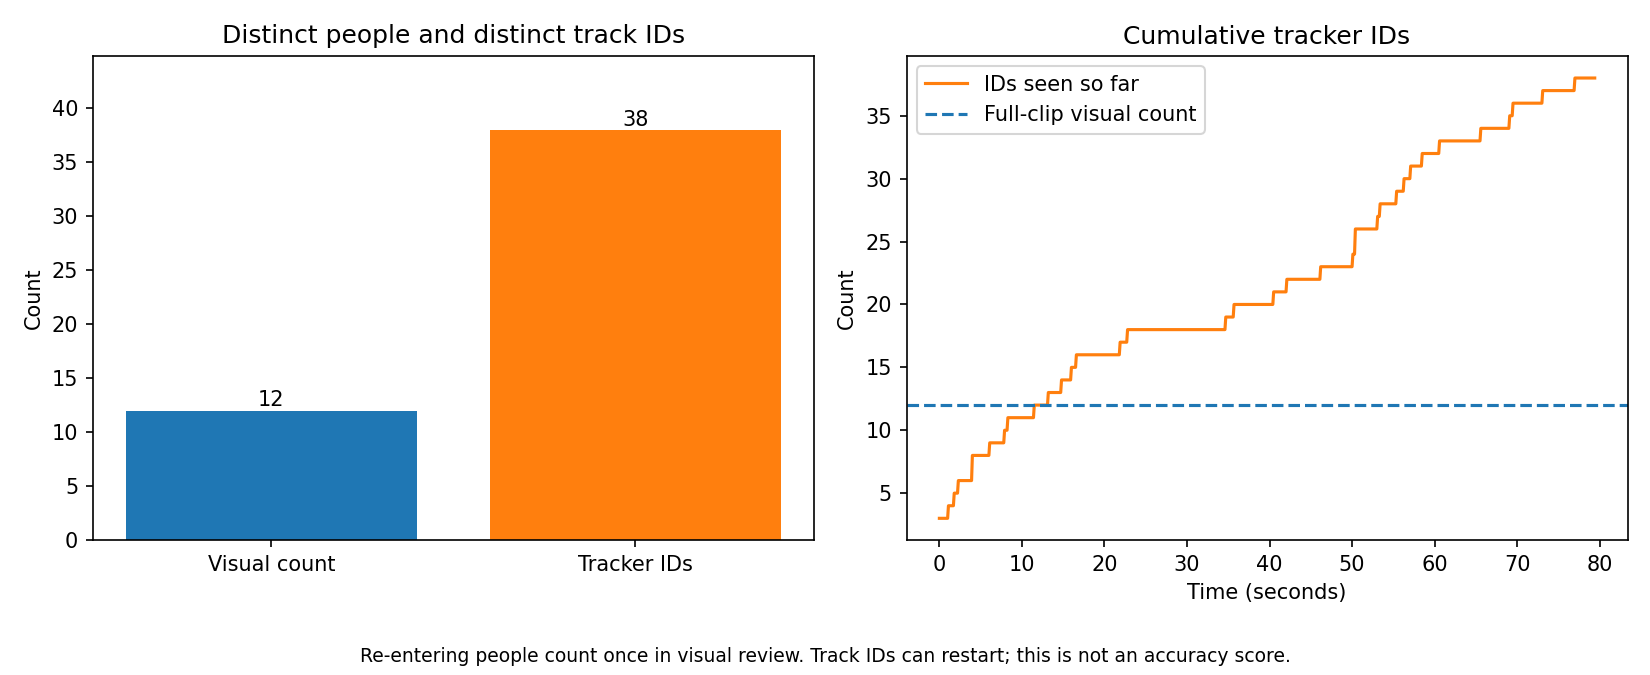

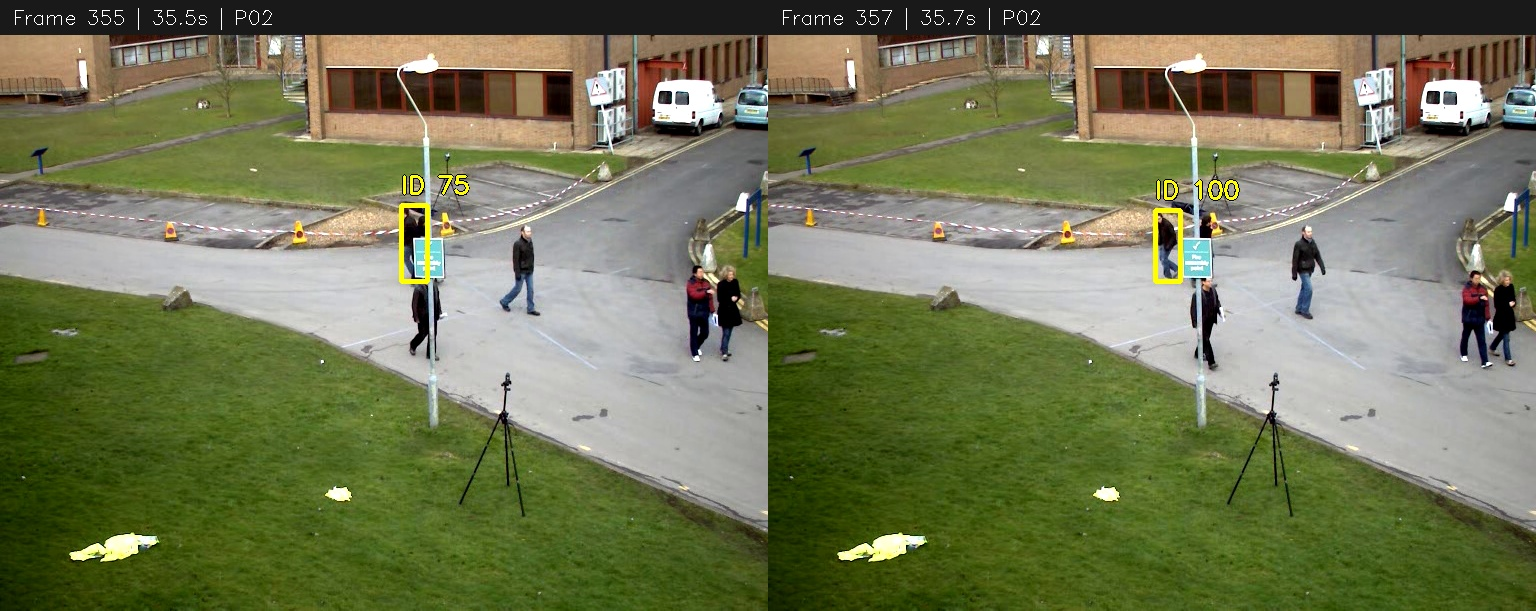

[Open the complete tracking video](outputs/people_tracked.mp4)

[Visual person ledger](data/manual_people.csv) | [Class notes](CLASS_NOTES.md)

In [11]:
from IPython.display import Image, Markdown, display

display(Image(filename=str(outputDir / "count_comparison.png"), width=1050))
display(Image(filename=str(outputDir / "id_switch.jpg"), width=1100))
display(Markdown("[Open the complete tracking video](outputs/people_tracked.mp4)"))
display(Markdown("[Visual person ledger](data/manual_people.csv) | [Class notes](CLASS_NOTES.md)"))

## What I noticed

The original run produced **38 tracker IDs**, while the separate visual review counted **12 distinct people**. The difference is **26**. Some people return to the scene, tracks can break, and short false tracks can add IDs. These are possible contributors; I did not label every box or assign every extra ID to a cause.

One visible example is **P02**, the person in a dark brown jacket and blue jeans. The person has **ID 75 at frame 355** and **ID 100 at frame 357**. The person passes behind the central pole/sign while another person crosses nearby. Occlusion and changed detection boxes likely interrupted the match. The identity change is observed; the cause is an explanation from the scene.

Frame numbers start at **0**. Frame 357 is **35.7 seconds** into the video (the 358th frame). The class calls this a new-ID switch; more specifically, it is a broken track receiving a new ID. This single example is not a measured total ID-switch rate.

The visual count is a review estimate, not official dataset ground truth. No accuracy, mAP, MOTA or IDF1 score is claimed. Changing the input, weights, tracker settings or library versions requires reviewing the manual comparison and ID-change notes again.